# Partie B — Optimisation des hyperparamètres

## Objectif du notebook

Ce notebook réalise l'exemple pratique demandé dans la Partie B du travail : appliquer une méthode d'optimisation des hyperparamètres aux données de l'exemple de jeux en ligne du cours, avec une variable cible **Y continue**.

- **Données utilisées :** le fichier d'entraînement fourni dans le cours (`clv_mobile_data_train.txt`).
- **Type de problème :** régression, et non classification.
- **Modèle :** `RandomForestRegressor`.
- **Méthode d'optimisation appliquée :** optimisation bayésienne avec `BayesSearchCV`.
- **Validation :** séparation entraînement/validation, puis validation croisée à 5 plis sur la partie entraînement.
- **Mesures :** RMSE, MAE et R².

> **Point important :** le fichier Kaggle de la Partie A et son Y catégoriel (1, 2, 3, 4) ne doivent pas être utilisés ici. Ne pas générer de données artificielles avec `make_classification` ou `make_regression` : l'expérience doit utiliser le fichier de cours indiqué ci-dessous.

Le chemin du fichier est défini dans la première section de code. Si le fichier est déplacé, il faudra modifier uniquement cette variable.

## 1. Les trois grandes méthodes d'optimisation

La Partie B demande de décrire trois méthodes. Les trois méthodes suivantes sont présentées dans ce notebook; l'exemple pratique utilise la troisième.

### 1.1 Grid Search (recherche par grille)

Grid Search définit à l'avance une liste de valeurs pour chaque hyperparamètre et teste toutes les combinaisons possibles. La méthode est simple à comprendre et permet une comparaison systématique. Cependant, le nombre d'essais augmente rapidement lorsque le nombre d'hyperparamètres ou de valeurs possibles augmente.

### 1.2 Random Search (recherche aléatoire)

Random Search tire aléatoirement des combinaisons dans des distributions ou des intervalles définis. Contrairement à Grid Search, il n'est pas nécessaire de tester toutes les combinaisons. Cette méthode peut donc explorer plus efficacement un grand espace de recherche lorsque le budget de calcul est limité. Le résultat dépend notamment du nombre d'essais et de la graine aléatoire.

### 1.3 Bayesian Optimization (optimisation bayésienne)

L'optimisation bayésienne utilise les résultats des essais précédents pour guider le choix des prochains hyperparamètres. Elle construit un modèle probabiliste de la relation entre les hyperparamètres et la performance, puis sélectionne de nouvelles combinaisons prometteuses. Elle cherche ainsi à réduire le nombre d'évaluations nécessaires. Dans ce notebook, elle est appliquée avec `BayesSearchCV` de la bibliothèque `scikit-optimize`.

### Méthode retenue pour l'expérience

L'optimisation bayésienne est retenue pour ajuster les hyperparamètres d'une forêt aléatoire de régression. Les autres méthodes sont décrites pour répondre à la comparaison théorique demandée; il n'est pas nécessaire d'entraîner trois modèles différents pour satisfaire le point 3 du PDF.

## 2. Packages requis

Exécuter la cellule suivante une seule fois si les bibliothèques nécessaires ne sont pas installées. Les imports utilisés dans le notebook sont ensuite regroupés dans la cellule suivante.

Bibliothèques principales : `numpy`, `pandas`, `scikit-learn`, `scikit-optimize`, `matplotlib` et `joblib`.

In [ ]:
# Décommenter et exécuter cette ligne si des packages sont manquants.
# %pip install numpy pandas scikit-learn scikit-optimize matplotlib joblib

In [1]:
# ============================================================
# 1) Imports et paramètres généraux
# ============================================================

from pathlib import Path
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from skopt import BayesSearchCV
from skopt.space import Integer, Real

# Graine aléatoire pour rendre les résultats reproductibles.
RANDOM_STATE = 42

# Chemin exact du fichier de données du cours fourni.
DATA_PATH = Path(
    r"C:\Users\Stephen\Desktop\Math60600数据挖掘课件\documents_etudiants_A2026\donnees\clv_mobile_data_train.txt"
)

# Les résultats seront enregistrés dans un dossier créé dans le répertoire courant.
OUTPUT_DIR = Path.cwd() / "partB_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Laisser vide par défaut. Ajouter ici uniquement les colonnes qui sont clairement
# des identifiants non explicatifs et qui ne font pas partie des variables du cours.
COLUMNS_TO_EXCLUDE = []

print("Chemin des données :", DATA_PATH)
print("Dossier de sortie :", OUTPUT_DIR.resolve())

Chemin des données : C:\Users\Stephen\Desktop\Math60600数据挖掘课件\documents_etudiants_A2026\donnees\clv_mobile_data_train.txt
Dossier de sortie : C:\Users\Stephen\partB_outputs


## 3. Charger et vérifier les données du cours

Le fichier est lu en essayant plusieurs séparateurs courants (espaces, tabulations, virgules et points-virgules). Le code vérifie ensuite que la colonne cible `y` existe et qu'elle peut être convertie en variable numérique.

Les lignes dont `y` est manquant ou non numérique sont retirées, car elles ne peuvent pas servir à entraîner un modèle de régression. Les colonnes entièrement vides sont également retirées.

In [2]:
# ============================================================
# 2) Lecture robuste du fichier de données
# ============================================================

def read_course_data(file_path: Path) -> pd.DataFrame:
    """Lire le fichier du cours et identifier automatiquement son séparateur."""
    if not file_path.exists():
        raise FileNotFoundError(
            "Le fichier de données est introuvable. Vérifiez DATA_PATH.\n"
            f"Chemin actuellement utilisé : {file_path}"
        )

    # Tester plusieurs formats. On conserve les lectures qui contiennent une colonne y.
    separators = [None, r"\s+", "\t", ";", ","]
    valid_candidates = []

    for separator in separators:
        try:
            candidate = pd.read_csv(
                file_path,
                sep=separator,
                engine="python",
                quotechar='"'
            )
            candidate.columns = [str(col).strip() for col in candidate.columns]
            candidate = candidate.dropna(axis=1, how="all")

            y_columns = [col for col in candidate.columns if col.strip().lower() == "y"]
            if len(y_columns) == 1 and candidate.shape[1] >= 2:
                # Favoriser une lecture avec plusieurs colonnes utiles et peu de valeurs manquantes.
                missing_cells = int(candidate.isna().sum().sum())
                score = (candidate.shape[1], -missing_cells)
                valid_candidates.append((score, candidate, separator))
        except Exception:
            continue

    if not valid_candidates:
        raise ValueError(
            "Impossible de lire le fichier avec les séparateurs testés ou de trouver la colonne 'y'. "
            "Vérifiez le format du fichier et la présence d'un en-tête contenant y."
        )

    valid_candidates.sort(key=lambda item: item[0], reverse=True)
    _, data, detected_separator = valid_candidates[0]

    # Uniformiser le nom de la variable cible.
    target_name = [col for col in data.columns if col.strip().lower() == "y"][0]
    data = data.rename(columns={target_name: "y"})

    print("Séparateur détecté :", repr(detected_separator))
    return data


df = read_course_data(DATA_PATH)

print("\nDimensions initiales :", df.shape)
print("Variables disponibles :")
print(df.columns.tolist())
print("\nAperçu des données :")
display(df.head())

print("\nTypes des variables :")
display(df.dtypes.to_frame(name="Type"))

Séparateur détecté : None

Dimensions initiales : (5000, 17)
Variables disponibles :
['numsessions', 'numdays', 'numpurchases', 'totpurchases', 'totplaytime', 'totscore', 'numlives', 'numelements', 'difflevel', 'skill1', 'skill2', 'country', 'opsys', 'acquis', 'trendsession', 'trendpurchase', 'y']

Aperçu des données :


,numsessions,numdays,numpurchases,totpurchases,totplaytime,totscore,numlives,numelements,difflevel,skill1,skill2,country,opsys,acquis,trendsession,trendpurchase,y
1,3,5,1,2.000000,202.168295,94.783740,24,14,2,0.369258,0.553046,6,1,0,1.491253,-0.066645,19.488203
2,12,7,3,2.000000,413.911718,104.587668,28,21,2,0.603684,0.379317,2,0,0,2.570440,2.816153,25.841992
3,2,4,3,13.110147,130.995568,98.178186,21,18,2,0.438464,0.445509,1,1,0,1.539911,1.371886,33.727202
4,6,6,3,21.709514,207.446863,100.547096,37,20,2,0.489058,0.519593,1,1,0,2.501270,0.612645,24.367095
5,6,7,4,7.212596,214.583872,107.447260,33,23,2,0.534398,0.675010,2,1,0,0.921289,0.797996,34.564927



Types des variables :


,Type
numsessions,int64
numdays,int64
numpurchases,int64
totpurchases,float64
totplaytime,float64
totscore,float64
numlives,int64
numelements,int64
difflevel,int64
skill1,float64


## 4. Préparer les variables explicatives et la cible continue

La variable `y` est convertie en numérique. Les variables explicatives sont séparées en variables numériques et catégorielles. Les valeurs manquantes seront imputées à l'intérieur d'un pipeline afin d'éviter une fuite d'information entre les plis de validation croisée.

- Variables numériques : imputation par la médiane.
- Variables catégorielles : imputation par la modalité la plus fréquente, puis encodage One-Hot.
- Une forêt aléatoire ne nécessite pas de standardisation des variables numériques.

Le code affiche le nombre de valeurs distinctes de `y`. Si les valeurs correspondent exactement aux quatre catégories 1, 2, 3 et 4 de la Partie A, l'exécution s'arrête pour éviter d'utiliser par erreur le mauvais Y.

In [3]:
# ============================================================
# 3) Nettoyage et séparation de X et y
# ============================================================

# Convertir y en numérique.
y_numeric = pd.to_numeric(df["y"], errors="coerce")
valid_y = y_numeric.notna()
number_removed = int((~valid_y).sum())

if number_removed > 0:
    print(f"Lignes retirées car y est manquant ou non numérique : {number_removed}")

# Garder uniquement les lignes pour lesquelles y est utilisable.
df = df.loc[valid_y].copy()
y = y_numeric.loc[valid_y].astype(float)

# Séparer les variables explicatives de la cible.
X = df.drop(columns=["y"]).copy()

# Retirer les colonnes entièrement vides.
X = X.dropna(axis=1, how="all")

# Exclure éventuellement des identifiants non explicatifs, après vérification.
missing_exclusions = [col for col in COLUMNS_TO_EXCLUDE if col not in X.columns]
if missing_exclusions:
    print("Colonnes à exclure non trouvées (ignorées) :", missing_exclusions)

columns_to_drop = [col for col in COLUMNS_TO_EXCLUDE if col in X.columns]
if columns_to_drop:
    X = X.drop(columns=columns_to_drop)
    print("Colonnes explicitement exclues :", columns_to_drop)

# Convertir les colonnes qui sont presque entièrement numériques.
for col in X.columns:
    converted = pd.to_numeric(X[col], errors="coerce")
    original_non_missing = X[col].notna().sum()
    if original_non_missing > 0:
        numeric_ratio = converted.notna().sum() / original_non_missing
        if numeric_ratio >= 0.95:
            X[col] = converted

if X.shape[1] == 0:
    raise ValueError("Aucune variable explicative n'a été trouvée après le nettoyage.")

if y.nunique() < 2:
    raise ValueError("La variable y doit contenir au moins deux valeurs distinctes.")

unique_y = set(pd.unique(y))
if len(unique_y) == 4 and unique_y.issubset({1.0, 2.0, 3.0, 4.0}):
    raise ValueError(
        "Le Y détecté contient exactement les catégories 1, 2, 3 et 4 de la Partie A. "
        "La Partie B exige le Y continu de l'exemple du cours. Vérifiez le fichier utilisé."
    )

if y.nunique() <= 10:
    warnings.warn(
        "La variable y possède 10 valeurs distinctes ou moins. Vérifiez qu'il s'agit bien "
        "du Y continu demandé pour la Partie B.",
        UserWarning
    )

print("Dimensions de X :", X.shape)
print("Nombre d'observations de y :", len(y))
print("Nombre de valeurs distinctes de y :", y.nunique())
print("\nRésumé statistique de y :")
display(y.describe().to_frame(name="y"))

print("\nTypes des variables explicatives après conversion :")
display(X.dtypes.to_frame(name="Type"))

print("\nValeurs manquantes dans X (10 premières colonnes) :")
display(X.isna().sum().head(10).to_frame(name="Valeurs manquantes"))

Dimensions de X : (5000, 16)
Nombre d'observations de y : 5000
Nombre de valeurs distinctes de y : 5000

Résumé statistique de y :


,y
count,5000.000000
mean,30.689982
std,12.517667
min,10.457666
25%,21.742716
50%,27.956267
75%,37.118507
max,106.716221



Types des variables explicatives après conversion :


,Type
numsessions,int64
numdays,int64
numpurchases,int64
totpurchases,float64
totplaytime,float64
totscore,float64
numlives,int64
numelements,int64
difflevel,int64
skill1,float64



Valeurs manquantes dans X (10 premières colonnes) :


,Valeurs manquantes
numsessions,0
numdays,0
numpurchases,0
totpurchases,0
totplaytime,0
totscore,0
numlives,0
numelements,0
difflevel,0
skill1,0


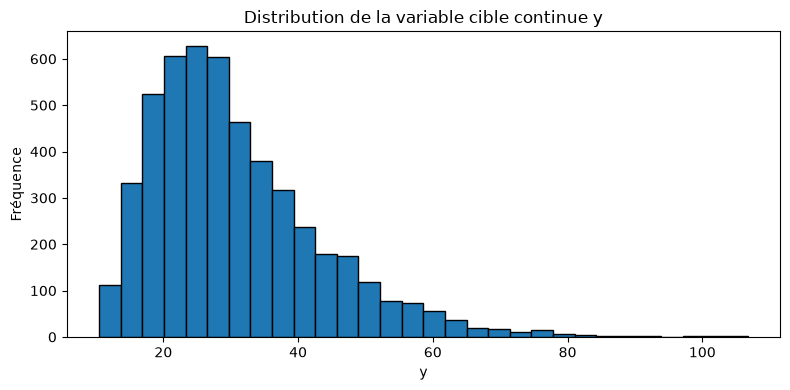

In [4]:
# Visualiser la distribution de la variable cible continue.
plt.figure(figsize=(8, 4))
plt.hist(y, bins=30, edgecolor="black")
plt.title("Distribution de la variable cible continue y")
plt.xlabel("y")
plt.ylabel("Fréquence")
plt.tight_layout()
plt.show()

## 5. Séparer les données

Une partie des observations est réservée à l'évaluation finale. La recherche des hyperparamètres est effectuée uniquement sur l'ensemble d'entraînement, au moyen d'une validation croisée à 5 plis. L'ensemble de validation ne sert donc pas à choisir les hyperparamètres.

In [5]:
# ============================================================
# 4) Séparation entraînement / validation
# ============================================================

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("X_train :", X_train.shape)
print("X_valid :", X_valid.shape)
print("y_train :", y_train.shape)
print("y_valid :", y_valid.shape)

X_train : (4000, 16)
X_valid : (1000, 16)
y_train : (4000,)
y_valid : (1000,)


## 6. Construire le pipeline de prétraitement et le modèle

Le prétraitement est intégré dans un `Pipeline`. Ainsi, les médianes, les modalités les plus fréquentes et l'encodage sont ajustés uniquement sur les données d'entraînement de chaque pli de validation croisée.

Le modèle est `RandomForestRegressor`, car `y` est continu.

In [6]:
# ============================================================
# 5) Prétraitement des variables et modèle de régression
# ============================================================

numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [col for col in X_train.columns if col not in numeric_features]

transformers = []

if numeric_features:
    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ])
    transformers.append(("num", numeric_pipeline, numeric_features))

if categorical_features:
    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    transformers.append(("cat", categorical_pipeline, categorical_features))

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

# n_jobs=1 dans le modèle pour éviter de lancer du parallélisme imbriqué
# puisque BayesSearchCV utilisera lui-même n_jobs=-1.
regression_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

print("Variables numériques :", numeric_features)
print("Variables catégorielles :", categorical_features)
print("Modèle : RandomForestRegressor")

Variables numériques : ['numsessions', 'numdays', 'numpurchases', 'totpurchases', 'totplaytime', 'totscore', 'numlives', 'numelements', 'difflevel', 'skill1', 'skill2', 'country', 'opsys', 'acquis', 'trendsession', 'trendpurchase']
Variables catégorielles : []
Modèle : RandomForestRegressor


## 7. Établir un modèle de référence

Avant l'optimisation, un modèle de forêt aléatoire avec des paramètres de base est ajusté. Il servira de référence pour vérifier si l'optimisation améliore les résultats sur l'ensemble de validation.

In [7]:
# ============================================================
# 6) Modèle de référence sans optimisation
# ============================================================

baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_valid)

baseline_rmse = np.sqrt(mean_squared_error(y_valid, baseline_predictions))
baseline_mae = mean_absolute_error(y_valid, baseline_predictions)
baseline_r2 = r2_score(y_valid, baseline_predictions)

print("Résultats du modèle de référence")
print(f"RMSE : {baseline_rmse:.4f}")
print(f"MAE  : {baseline_mae:.4f}")
print(f"R²   : {baseline_r2:.4f}")

Résultats du modèle de référence
RMSE : 5.6644
MAE  : 4.2764
R²   : 0.7874


## 8. Optimisation bayésienne des hyperparamètres

`BayesSearchCV` explore l'espace d'hyperparamètres de manière séquentielle. À chaque étape, les résultats précédents aident à choisir les prochains essais.

Les hyperparamètres optimisés sont :

- `n_estimators` : nombre d'arbres;
- `max_depth` : profondeur maximale des arbres;
- `min_samples_split` : nombre minimal d'observations nécessaire pour diviser un nœud;
- `min_samples_leaf` : nombre minimal d'observations dans une feuille;
- `max_features` : proportion des variables considérées lors d'une division.

Le critère d'optimisation est le RMSE en validation croisée. Scikit-learn maximise les scores; c'est pourquoi le code utilise `neg_root_mean_squared_error`, soit l'opposé du RMSE.

In [8]:
# ============================================================
# 7) Recherche bayésienne avec validation croisée
# ============================================================

# Validation croisée à 5 plis, avec mélange des observations.
cv_strategy = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Domaine de recherche des hyperparamètres.
search_spaces = {
    "regressor__n_estimators": Integer(100, 400),
    "regressor__max_depth": Integer(3, 30),
    "regressor__min_samples_split": Integer(2, 20),
    "regressor__min_samples_leaf": Integer(1, 10),
    "regressor__max_features": Real(0.50, 1.00)
}

bayes_search = BayesSearchCV(
    estimator=regression_pipeline,
    search_spaces=search_spaces,
    n_iter=20,  # Nombre d'essais bayésiens
    scoring="neg_root_mean_squared_error",
    cv=cv_strategy,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    refit=True,
    return_train_score=True,
    verbose=1
)

print("Début de l'optimisation bayésienne...")
bayes_search.fit(X_train, y_train)

print("\nMeilleurs hyperparamètres :")
for parameter, value in bayes_search.best_params_.items():
    print(f"{parameter}: {value}")

best_cv_rmse = -bayes_search.best_score_
print(f"\nMeilleur RMSE moyen en validation croisée : {best_cv_rmse:.4f}")

Début de l'optimisation bayésienne...
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds fo

## 9. Évaluer le modèle optimisé sur l'ensemble de validation

Le meilleur pipeline obtenu par validation croisée est évalué sur les observations mises de côté au début. Ces observations n'ont pas participé à la recherche bayésienne.

In [9]:
# ============================================================
# 8) Évaluation finale sur l'ensemble de validation
# ============================================================

best_model = bayes_search.best_estimator_
optimized_predictions = best_model.predict(X_valid)

optimized_rmse = np.sqrt(mean_squared_error(y_valid, optimized_predictions))
optimized_mae = mean_absolute_error(y_valid, optimized_predictions)
optimized_r2 = r2_score(y_valid, optimized_predictions)

comparison = pd.DataFrame({
    "Modèle": ["Forêt aléatoire de référence", "Forêt aléatoire optimisée (Bayesian Optimization)"],
    "RMSE_validation": [baseline_rmse, optimized_rmse],
    "MAE_validation": [baseline_mae, optimized_mae],
    "R2_validation": [baseline_r2, optimized_r2]
})

print("Comparaison des modèles sur le même ensemble de validation :")
display(comparison)

if optimized_rmse < baseline_rmse:
    print("L'optimisation bayésienne améliore le RMSE par rapport au modèle de référence.")
else:
    print("L'optimisation bayésienne n'améliore pas le RMSE sur cet ensemble de validation.")
    print("Il faut rapporter le résultat observé sans prétendre à une amélioration.")

Comparaison des modèles sur le même ensemble de validation :


,Modèle,RMSE_validation,MAE_validation,R2_validation
0,Forêt aléatoire de référence,5.664401,4.276439,0.787366
1,Forêt aléatoire optimisée (Bayesian Optimization),5.614820,4.259700,0.791072


L'optimisation bayésienne améliore le RMSE par rapport au modèle de référence.


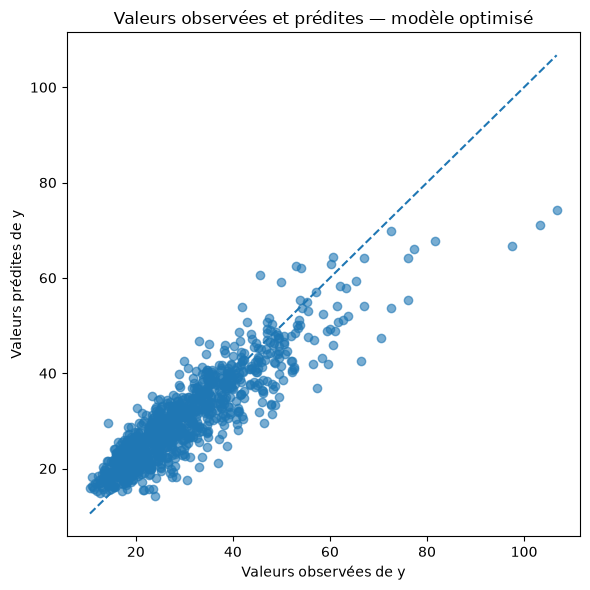

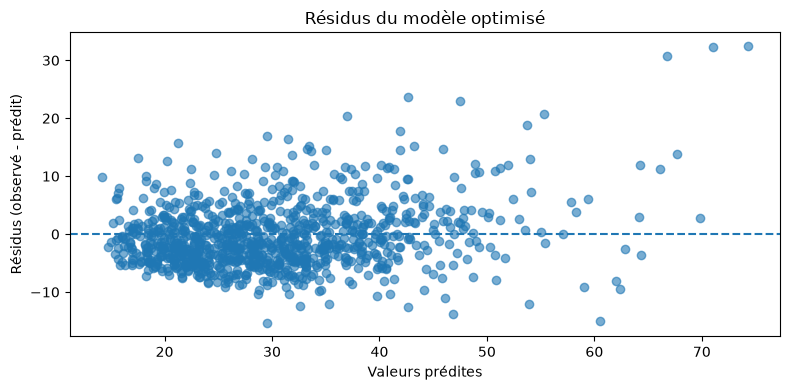

In [10]:
# Visualisation : valeurs observées contre valeurs prédites.
plt.figure(figsize=(6, 6))
plt.scatter(y_valid, optimized_predictions, alpha=0.6)
min_value = min(float(y_valid.min()), float(np.min(optimized_predictions)))
max_value = max(float(y_valid.max()), float(np.max(optimized_predictions)))
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")
plt.title("Valeurs observées et prédites — modèle optimisé")
plt.xlabel("Valeurs observées de y")
plt.ylabel("Valeurs prédites de y")
plt.tight_layout()
plt.show()

# Visualisation des résidus.
residuals = y_valid.to_numpy() - optimized_predictions
plt.figure(figsize=(8, 4))
plt.scatter(optimized_predictions, residuals, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.title("Résidus du modèle optimisé")
plt.xlabel("Valeurs prédites")
plt.ylabel("Résidus (observé - prédit)")
plt.tight_layout()
plt.show()

## 10. Examiner les essais et enregistrer les résultats

La table suivante présente les meilleurs essais de la recherche bayésienne, classés selon le RMSE de validation croisée. Le modèle final et les résultats sont ensuite enregistrés dans le dossier `partB_outputs`.

In [ ]:
# ============================================================
# 9) Résumé de la recherche et sauvegarde des résultats
# ============================================================

cv_results = pd.DataFrame(bayes_search.cv_results_).copy()
cv_results["CV_RMSE"] = -cv_results["mean_test_score"]
cv_results = cv_results.sort_values("CV_RMSE", ascending=True)

top_trials = cv_results[["rank_test_score", "CV_RMSE", "params"]].head(10)
print("Les 10 meilleurs essais :")
display(top_trials)

# Enregistrer la comparaison des modèles et les essais de validation croisée.
comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
cv_results.to_csv(OUTPUT_DIR / "bayesian_search_cv_results.csv", index=False)

# Enregistrer le meilleur pipeline (prétraitement + modèle).
joblib.dump(best_model, OUTPUT_DIR / "best_random_forest_regressor.joblib")

# Enregistrer les valeurs observées et prédites sur l'ensemble de validation.
prediction_results = pd.DataFrame({
    "y_observe": y_valid.to_numpy(),
    "y_predit": optimized_predictions,
    "residu": residuals
})
prediction_results.to_csv(OUTPUT_DIR / "validation_predictions.csv", index=False)

print("\nFichiers enregistrés dans :", OUTPUT_DIR.resolve())
print("- model_comparison.csv")
print("- bayesian_search_cv_results.csv")
print("- best_random_forest_regressor.joblib")
print("- validation_predictions.csv")

## 11. Conclusion à compléter après l'exécution

Après avoir exécuté toutes les cellules, compléter le rapport avec les valeurs réellement affichées :

1. Le nombre d'observations et le nombre de variables explicatives utilisés.
2. Les hyperparamètres retenus par l'optimisation bayésienne.
3. Le RMSE, le MAE et le R² sur l'ensemble de validation.
4. La comparaison avec la forêt aléatoire de référence.
5. Une interprétation honnête : préciser si l'optimisation améliore ou non les résultats.

**Attention :** les chiffres ne peuvent pas être remplis avant l'exécution sur le fichier local. Ne pas reprendre les anciennes exactitudes (accuracy) de l'expérience de classification artificielle : elles ne correspondent pas à cette tâche de régression.

### Vérifications à faire avant la remise

- Confirmer que le fichier chargé est bien le fichier du cours avec Y continu.
- Vérifier les noms des variables et décider, à partir du dictionnaire de données du cours, si une colonne d'identifiant doit être exclue.
- Exécuter le notebook de haut en bas avec `Kernel > Restart & Run All`.
- Dans le rapport écrit, présenter au moins trois ressources pertinentes et complémentaires : le notebook ne remplace pas cette partie bibliographique.